In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats


In [3]:
df = pd.read_csv('/content/vehicles.csv')
df.head()

/tmp/ipykernel_7430/2047678922.py:1: DtypeWarning: Columns (4,32,40) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/content/vehicles.csv')


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,NaN,NaN
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,...,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,NaN,NaN
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,NaN,NaN
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,...,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,NaN,NaN
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,NaN,NaN


In [4]:
df.tail()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
295446,7978316265,https://zanesville.craigslist.org/ctd/d/cambri...,zanesville / cambridge,https://zanesville.craigslist.org,13977,2016.0,subaru,forester,excellent,4 cylinders,...,OH,43725.0,US,17,https://images.craigslist.org/00P0P_g2md0GCU3A...,0,0,0,NaN,NaN
295447,7978068858,https://zanesville.craigslist.org/cto/d/rosevi...,zanesville / cambridge,https://zanesville.craigslist.org,5500,2004.0,chevrolet,2500 6.6 diesel,fair,8 cylinders,...,OH,43777.0,US,13,https://images.craigslist.org/00505_1czgViYDqY...,0,0,0,NaN,NaN
295448,7977713163,https://zanesville.craigslist.org/ctd/d/lake-c...,zanesville / cambridge,https://zanesville.craigslist.org,66800,2027.0,NaN,Mini-T Camper Van | Garageable RV,new,6 cylinders,...,MN,56055.0,US,24,https://images.craigslist.org/00X0X_9QkTWtjlxH...,1,0,0,NaN,NaN
295449,7977443604,https://zanesville.craigslist.org/cto/d/seneca...,zanesville / cambridge,https://zanesville.craigslist.org,5850,2017.0,chevrolet,traverse lt,good,6 cylinders,...,OH,43780.0,US,8,https://images.craigslist.org/00K0K_fuivMPDJfU...,0,0,0,NaN,NaN
295450,7976716941,https://zanesville.craigslist.org/ctd/d/cambri...,zanesville / cambridge,https://zanesville.craigslist.org,9977,2016.0,kia,rio,like new,4 cylinders,...,OH,43725.0,US,15,https://images.craigslist.org/00l0l_fuxA70bzlg...,0,0,0,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295425 non-null  float64
 6   manufacturer          284659 non-null  object 
 7   model                 292092 non-null  object 
 8   condition             159961 non-null  object 
 9   cylinders             215284 non-null  object 
 10  fuel                  294320 non-null  object 
 11  odometer              291415 non-null  float64
 12  title_status          288635 non-null  object 
 13  transmission          293895 non-null  object 
 14  VIN                   174332 non-null  object 
 15  

In [6]:
df.shape

(295451, 41)

In [7]:
df.isnull().sum()

,0
id,0
url,0
region,0
region_url,0
price,0
year,26
manufacturer,10792
model,3359
condition,135490
cylinders,80167


In [8]:
df['other_attributes'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/4152154825.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['other_attributes'].fillna('unknown',inplace=True)


In [9]:
df['monthly_payment'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2432717507.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['monthly_payment'].fillna('unknown',inplace=True)


In [10]:
df['image_urls'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/590128810.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['image_urls'].fillna('unknown',inplace=True)


In [11]:
df['address_country'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/292240200.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['address_country'].fillna('unknown',inplace=True)


In [12]:
df['address_postal_code'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/239471036.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['address_postal_code'].fillna('unknown',inplace=True)


In [13]:
df['address_state'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/1962738720.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['address_state'].fillna('unknown',inplace=True)


In [14]:
df['address_city'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/435589977.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['address_city'].fillna('unknown',inplace=True)


In [15]:
df['address_street'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3186660264.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['address_street'].fillna('unknown',inplace=True)


In [16]:
df['updated_date'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3508889608.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['updated_date'].fillna('unknown',inplace=True)


In [17]:
df['county'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3018668530.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['county'].fillna('unknown',inplace=True)
/tmp/ipykernel_7430/3018668530.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'unknown' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df['county'].fillna('unknown',inplace=True)


In [18]:
df['image_url'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3085317215.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['image_url'].fillna('unknown',inplace=True)


In [19]:
df['paint_color'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/369733975.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['paint_color'].fillna('unknown',inplace=True)


In [20]:
df['type'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2850327122.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['type'].fillna('unknown',inplace=True)


In [21]:
df['size'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/994540541.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['size'].fillna('unknown',inplace=True)
/tmp/ipykernel_7430/994540541.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'unknown' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df['size'].fillna('unknown',inplace=True)


In [22]:
df['drive'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2910124140.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['drive'].fillna('unknown',inplace=True)


In [23]:
df['VIN'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/1954110928.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['VIN'].fillna('unknown',inplace=True)


In [24]:
df['transmission'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3592285307.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['transmission'].fillna('unknown',inplace=True)


In [25]:
df['title_status'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3284659402.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['title_status'].fillna('unknown',inplace=True)


In [26]:
df['odometer'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2736525688.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['odometer'].fillna('unknown',inplace=True)
/tmp/ipykernel_7430/2736525688.py:1: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'unknown' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df['odometer'].fillna('unknown',inplace=True)


In [27]:
df['fuel'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2560042170.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['fuel'].fillna('unknown',inplace=True)


In [28]:
df['cylinders'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2154462234.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['cylinders'].fillna('unknown',inplace=True)


In [29]:
df['condition'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3837515590.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['condition'].fillna('unknown',inplace=True)


In [30]:
df['manufacturer'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/3436758228.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['manufacturer'].fillna('unknown',inplace=True)


In [31]:
df['model'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/2517629418.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['model'].fillna('unknown',inplace=True)


In [32]:
df['manufacturer'].fillna('unknown',inplace=True)

In [33]:
df['year'].fillna(df['year'].mean(),inplace=True)

/tmp/ipykernel_7430/2667233607.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['year'].fillna(df['year'].mean(),inplace=True)


In [34]:
df['lat'].fillna(df['lat'].mean(),inplace=True)

/tmp/ipykernel_7430/1929265479.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['lat'].fillna(df['lat'].mean(),inplace=True)


In [35]:
df['long'].fillna(df['long'].mean(),inplace=True)

/tmp/ipykernel_7430/2786962122.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['long'].fillna(df['long'].mean(),inplace=True)


In [36]:
df.isnull().sum()

,0
id,0
url,0
region,0
region_url,0
price,0
year,0
manufacturer,0
model,0
condition,0
cylinders,0


In [46]:
df['title'].fillna('unknown',inplace=True)

In [48]:
df['description'].fillna('unknown',inplace=True)

/tmp/ipykernel_7430/4027017077.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['description'].fillna('unknown',inplace=True)


In [49]:
df.isnull().sum()

,0
id,0
url,0
region,0
region_url,0
price,0
year,0
manufacturer,0
model,0
condition,0
cylinders,0


In [50]:
df.head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,unknown,unknown
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,...,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,unknown,unknown
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,unknown,unknown
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,...,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,unknown,unknown
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,unknown,unknown


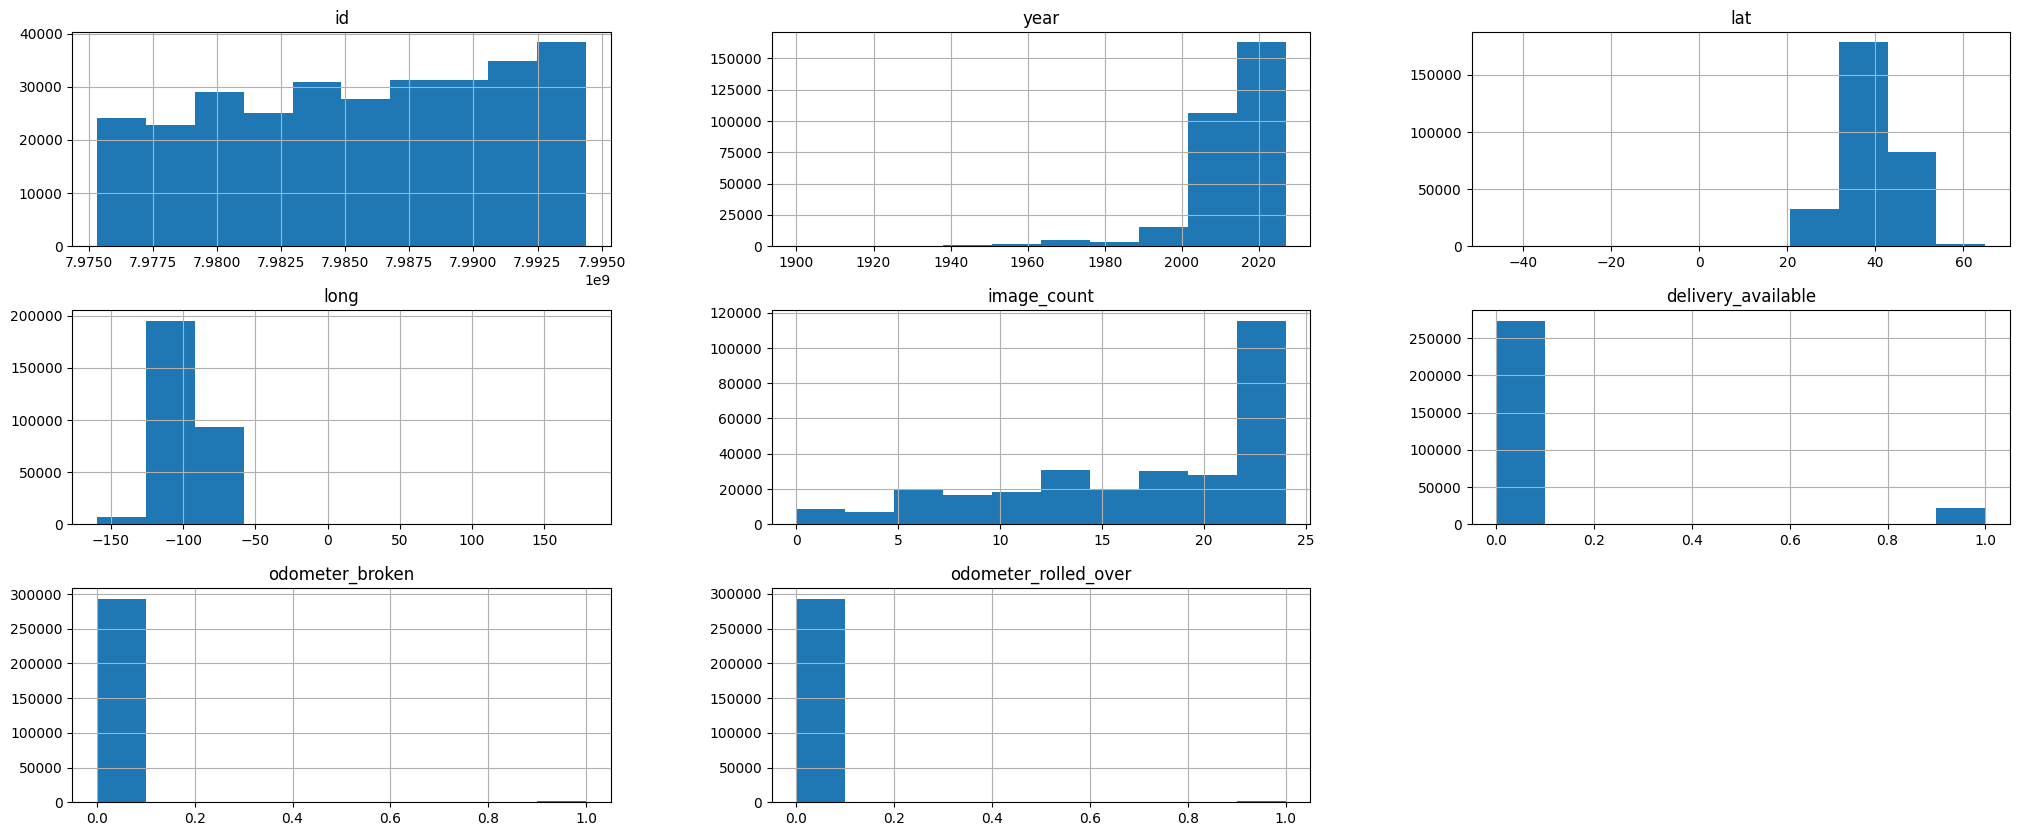

In [51]:
df.hist(figsize=(25,10))
plt.show()

In [52]:
df.sample(3)

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
18870,7976122425,https://albany.craigslist.org/ctd/d/rensselaer...,albany,https://albany.craigslist.org,11995,2015.0,audi,q5 20t quattro premium,excellent,other,...,NY,12144,US,23,https://images.craigslist.org/01212_dKFw9jqPGg...,0,0,0,unknown,unknown
196342,7985250141,https://portland.craigslist.org/cto/d/portland...,portland,https://portland.craigslist.org,12000,1984.0,chevrolet,silverado 2500,good,8 cylinders,...,OR,97223,US,5,https://images.craigslist.org/00M0M_bETz7eJwzF...,0,0,0,unknown,unknown
68458,7981026729,https://denver.craigslist.org/ctd/d/denver-200...,denver,https://denver.craigslist.org,12950,2008.0,chevrolet,tahoe 1/2 ton ls,excellent,8 cylinders,...,CO,80231,US,19,https://images.craigslist.org/00A0A_6f68fuQPAB...,0,0,0,unknown,unknown


In [53]:
df['id'].unique()

array([7994372850, 7994372787, 7994372559, ..., 7977713163, 7977443604,
       7976716941], shape=(295451,))

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295451 entries, 0 to 295450
Data columns (total 41 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    295451 non-null  int64  
 1   url                   295451 non-null  object 
 2   region                295451 non-null  object 
 3   region_url            295451 non-null  object 
 4   price                 295451 non-null  object 
 5   year                  295451 non-null  float64
 6   manufacturer          295451 non-null  object 
 7   model                 295451 non-null  object 
 8   condition             295451 non-null  object 
 9   cylinders             295451 non-null  object 
 10  fuel                  295451 non-null  object 
 11  odometer              295451 non-null  object 
 12  title_status          295451 non-null  object 
 13  transmission          295451 non-null  object 
 14  VIN                   295451 non-null  object 
 15  

In [55]:
df.head()

,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,address_state,address_postal_code,address_country,image_count,image_urls,delivery_available,odometer_broken,odometer_rolled_over,monthly_payment,other_attributes
0,7994372850,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,27999,2022.0,ford,explorer st,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00N0N_aBzbdTBI4c...,0,0,0,unknown,unknown
1,7994372787,https://sfbay.craigslist.org/cto/d/mill-valley...,SF bay area,https://sfbay.craigslist.org,2200,1969.0,volkswagen,bug,fair,4 cylinders,...,CA,94942,US,4,https://images.craigslist.org/00n0n_gNzbApFpKG...,0,0,0,unknown,unknown
2,7994372559,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,15999,2016.0,rover,sport,excellent,6 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00Z0Z_3KNlCaCAM2...,0,0,0,unknown,unknown
3,7994372553,https://sfbay.craigslist.org/cto/d/napa-1974-c...,SF bay area,https://sfbay.craigslist.org,12000,1974.0,cadillac,eldorado convertible,good,8 cylinders,...,CA,94581,US,8,https://images.craigslist.org/00s0s_4aCpejyeUW...,0,0,0,unknown,unknown
4,7994372166,https://sfbay.craigslist.org/ctd/d/sunnyvale-2...,SF bay area,https://sfbay.craigslist.org,18999,2009.0,dodge,challenger lc srt8,excellent,8 cylinders,...,CA,94088,US,20,https://images.craigslist.org/00T0T_4wec2Grzn3...,0,0,0,unknown,unknown


In [56]:
df.describe()

,id,year,lat,long,image_count,delivery_available,odometer_broken,odometer_rolled_over
count,2.954510e+05,295451.000000,295451.000000,295451.000000,295451.000000,295451.000000,295451.000000,295451.000000
mean,7.985641e+09,2012.771235,38.763646,-104.154990,17.094225,0.073288,0.006918,0.007761
std,5.481825e+06,11.579920,6.234142,19.686049,6.917641,0.260609,0.082888,0.087754
min,7.975321e+09,1900.000000,-46.156577,-159.719900,0.000000,0.000000,0.000000,0.000000
25%,7.980935e+09,2010.000000,34.061400,-121.465919,12.000000,0.000000,0.000000,0.000000
50%,7.985959e+09,2015.000000,38.848900,-110.945000,19.000000,0.000000,0.000000,0.000000
75%,7.990508e+09,2019.000000,43.593700,-84.463300,24.000000,0.000000,0.000000,0.000000
max,7.994391e+09,2027.000000,64.993698,178.877500,24.000000,1.000000,1.000000,1.000000


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


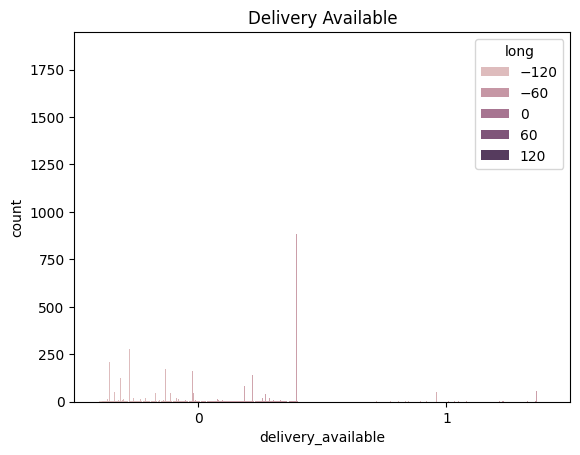

In [57]:
sns.countplot(x='delivery_available' , hue='long',data=df)
plt.title('Delivery Available')
plt.show()

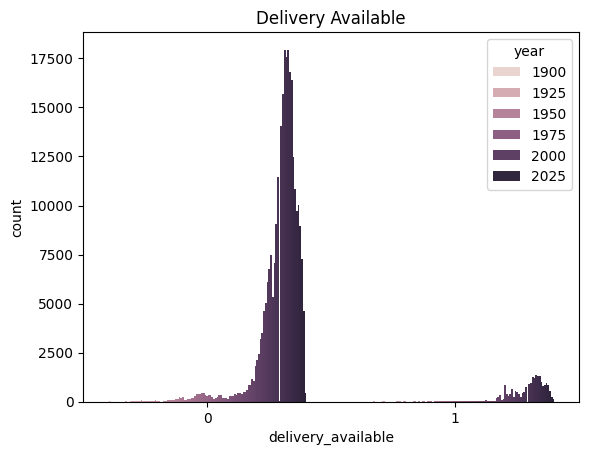

In [58]:
sns.countplot(x='delivery_available' , hue='year',data=df)
plt.title('Delivery Available')
plt.show()

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


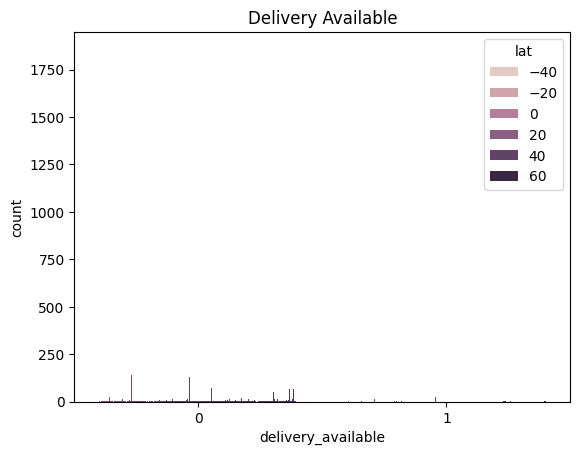

In [59]:
sns.countplot(x='delivery_available' , hue='lat',data=df)
plt.title('Delivery Available')
plt.show()

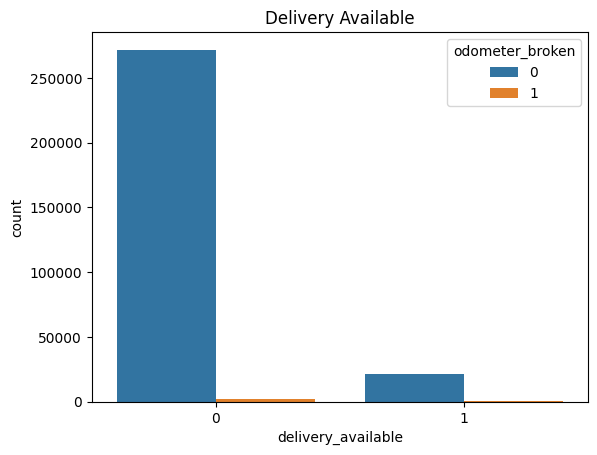

In [60]:
sns.countplot(x='delivery_available' , hue='odometer_broken',data=df)
plt.title('Delivery Available')
plt.show()

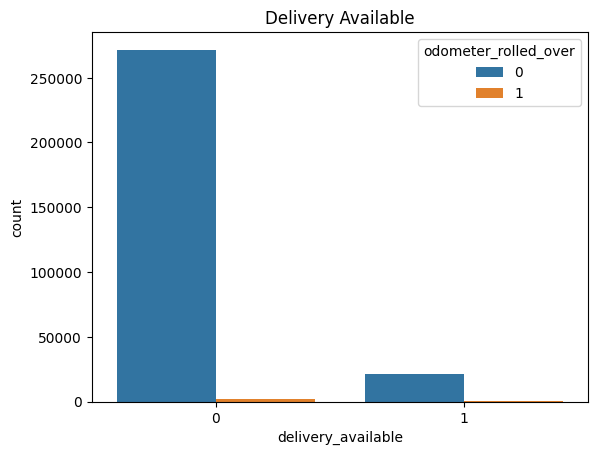

In [61]:
sns.countplot(x='delivery_available' , hue='odometer_rolled_over',data=df)
plt.title('Delivery Available')
plt.show()